# 03 · Evaluation, Explainability (SHAP) and Fairness Checks
**Project:** Early Disease Prediction Using Machine Learning on Health Data

A good score is not enough for a health model. We also need to know **why** it predicts what it predicts, **for whom** it works well, and **where** it fails. This notebook covers:

1. Final test performance with confidence intervals
2. Permutation importance
3. SHAP explanations (global, model comparison, dependence, single patients)
4. Performance across patient subgroups
5. Error analysis (who does the model miss?)

> **Disclaimer:** this is a student research project on partly synthetic data. It must **not** be used for clinical diagnosis or medical decisions without supervision by qualified medical professionals.

In [1]:
import sys, warnings
from pathlib import Path

# Find the project folder whether the notebook is opened from /notebooks or from the project root
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as C, data_utils as D, evaluate as E, viz

%matplotlib inline
viz.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
import joblib
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from src import explain, predict
from src.train import SLUG

## 0 · Load the saved models and the test set
These are the files written by notebook 02 (or by `python -m src.train`).

In [2]:
meta = predict.load_metadata()
best_name, threshold = meta["best_model"], meta["screening_threshold"]
models = {name: joblib.load(C.MODELS_DIR / f"{slug}.joblib") for name, slug in SLUG.items()}
train = pd.read_csv(C.PROCESSED_DIR / "train.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test.csv")
X_test, y_test = D.xy(test)
best = models[best_name]
proba = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
print(f"Best model: {best_name} | screening threshold: {threshold:.4f} | test rows: {len(test)}")

Best model: Logistic Regression | screening threshold: 0.3884 | test rows: 1000


## 1 · Test performance with confidence intervals
A single test AUC hides how much it could change with a different sample. The bootstrap re-samples the test set 1,000 times to show that spread.

In [3]:
rows = []
for name, p in proba.items():
    lo, hi = E.bootstrap_ci(y_test, p)
    rows.append({"model": name, "test ROC-AUC": roc_auc_score(y_test, p), "95% CI low": lo, "95% CI high": hi})
display(pd.DataFrame(rows).set_index("model"))

# paired bootstrap: is the selected model really better than the others?
rng = np.random.default_rng(C.RANDOM_STATE)
y = y_test.to_numpy()
diffs = {n: [] for n in proba if n != best_name}
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    base = roc_auc_score(y[idx], proba[best_name][idx])
    for n in diffs:
        diffs[n].append(base - roc_auc_score(y[idx], proba[n][idx]))
print(f"AUC difference: {best_name} minus the other model (paired bootstrap)")
pd.DataFrame({n: {"mean difference": np.mean(d), "95% CI low": np.percentile(d, 2.5),
                  "95% CI high": np.percentile(d, 97.5)} for n, d in diffs.items()}).T

,test ROC-AUC,95% CI low,95% CI high
model,,,
Logistic Regression,0.822,0.796,0.848
Random Forest,0.816,0.790,0.843
XGBoost,0.815,0.789,0.841


AUC difference: Logistic Regression minus the other model (paired bootstrap)


,mean difference,95% CI low,95% CI high
Random Forest,0.006,-0.001,0.014
XGBoost,0.007,0.001,0.013


If the interval for a difference includes 0, the two models cannot be told apart with this much test data.

## 2 · Permutation importance
We shuffle one feature at a time on the test set and see how much the AUC drops. A big drop means the model relies on that feature. Unlike SHAP, this looks only at the effect on accuracy.

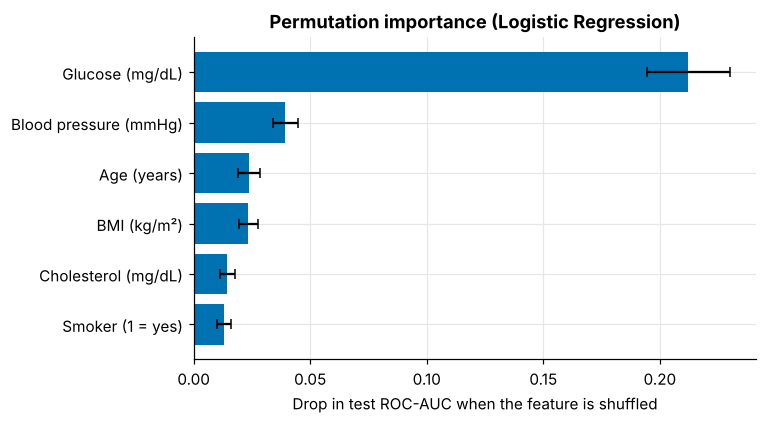

In [4]:
pi = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=30,
                            random_state=C.RANDOM_STATE, n_jobs=1)
order = np.argsort(pi.importances_mean)
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.barh([C.FEATURE_LABELS[C.FEATURES[i]] for i in order], pi.importances_mean[order],
        xerr=pi.importances_std[order], color=viz.BLUE, capsize=3)
ax.set(xlabel="Drop in test ROC-AUC when the feature is shuffled", title=f"Permutation importance ({best_name})")
viz.save_fig(fig, "permutation_importance"); plt.show()

## 3 · SHAP: what drives the predictions?
SHAP gives each feature a share of the credit (or blame) for every single prediction. Positive values push the risk up, negative values push it down. For Logistic Regression the values are in log-odds units.

### 3.1 Global view for the selected model

SHAP output space: log-odds


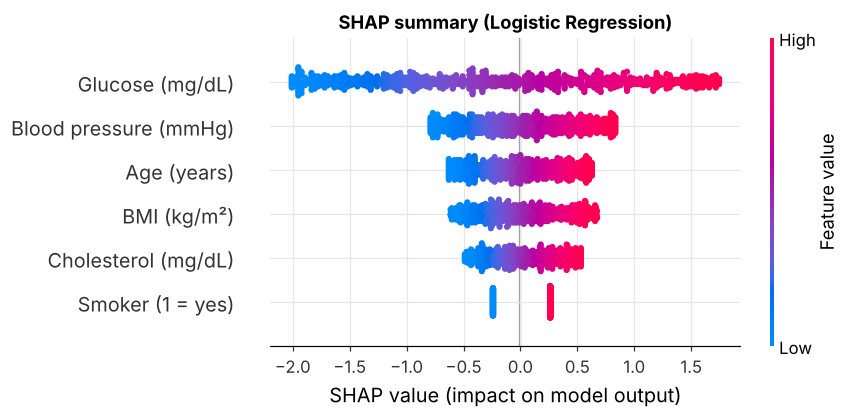

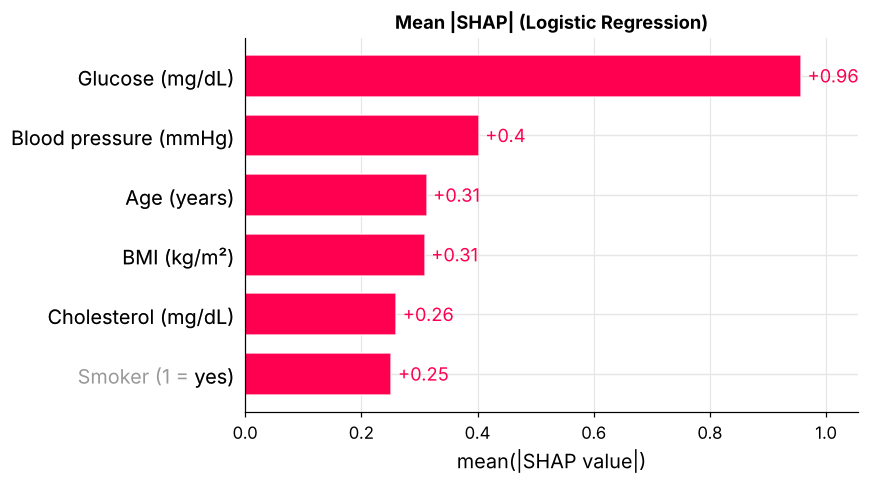

In [5]:
expl, space = explain.global_explanation(best, X_test, train[C.FEATURES])
print("SHAP output space:", space)
fig = explain.plot_beeswarm(expl, f"SHAP summary ({best_name})")
viz.save_fig(fig, "shap_beeswarm"); plt.show()
fig = explain.plot_bar(expl, f"Mean |SHAP| ({best_name})")
viz.save_fig(fig, "shap_bar"); plt.show()

How to read the beeswarm: each dot is one patient. Dots to the right raised the predicted risk, dots to the left lowered it. Red means a high feature value, blue a low one. High glucose (red) sits far to the right, so high glucose raises risk strongly.

### 3.2 Do all three models agree on what matters?
Each model's mean |SHAP| is shown as a share of its total, so models with different output scales can be compared.

,Logistic Regression,Random Forest,XGBoost
share of total importance (%),,,
Glucose (mg/dL),38.4,46.5,39.9
Blood pressure (mmHg),16.1,16.0,15.4
Age (years),12.5,12.2,12.7
BMI (kg/m²),12.4,11.8,12.7
Cholesterol (mg/dL),10.4,8.8,10.2
Smoker (1 = yes),10.1,4.8,9.2


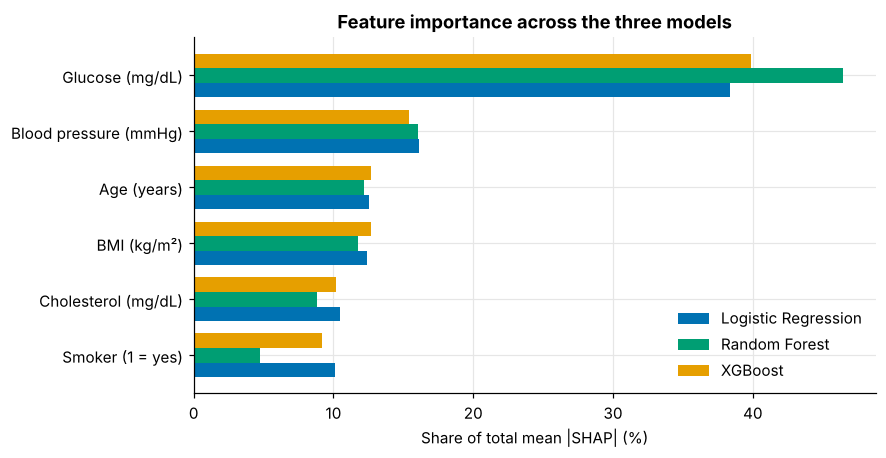

In [6]:
expl_by_model, shares = {}, {}
for name, m in models.items():
    e, sp = explain.global_explanation(m, X_test, train[C.FEATURES])
    expl_by_model[name] = e
    s = explain.mean_abs_shap(e)
    shares[name] = s / s.sum()
share_df = pd.DataFrame(shares).loc[explain.mean_abs_shap(expl).index]
display((share_df * 100).round(1).rename_axis("share of total importance (%)"))
fig, ax = plt.subplots(figsize=(8, 4.2))
y_pos = np.arange(len(share_df))[::-1]
for k, name in enumerate(share_df.columns):
    ax.barh(y_pos + (k - 1) * 0.26, share_df[name] * 100, 0.26, color=viz.MODEL_COLORS[name], label=name)
ax.set_yticks(y_pos, share_df.index)
ax.set(xlabel="Share of total mean |SHAP| (%)", title="Feature importance across the three models")
ax.legend(loc="lower right")
viz.save_fig(fig, "shap_importance_compare"); plt.show()

All three models rank the features the same way, with glucose far ahead. That agreement is reassuring: the finding does not depend on one particular algorithm.

### 3.3 Dependence plots (XGBoost)
Logistic Regression can only draw straight lines, so we use XGBoost to check whether the real effect bends. Each dot is a patient; colour shows age.

<Figure size 638x440 with 0 Axes>

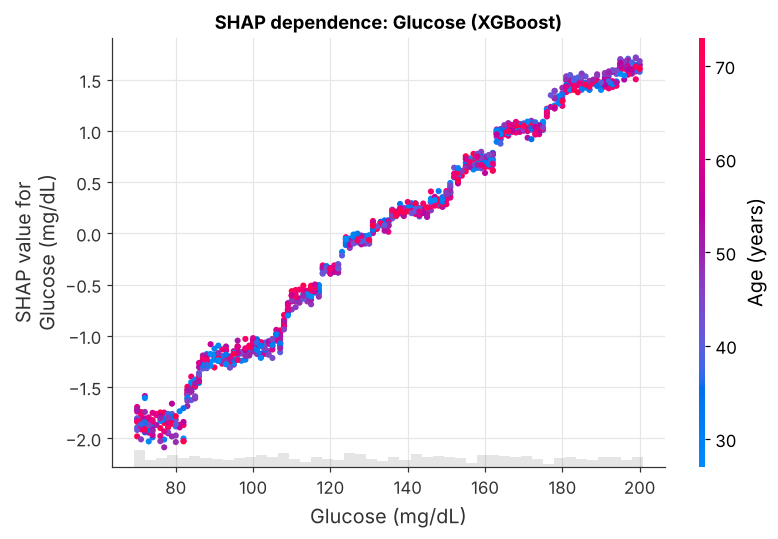

<Figure size 638x440 with 0 Axes>

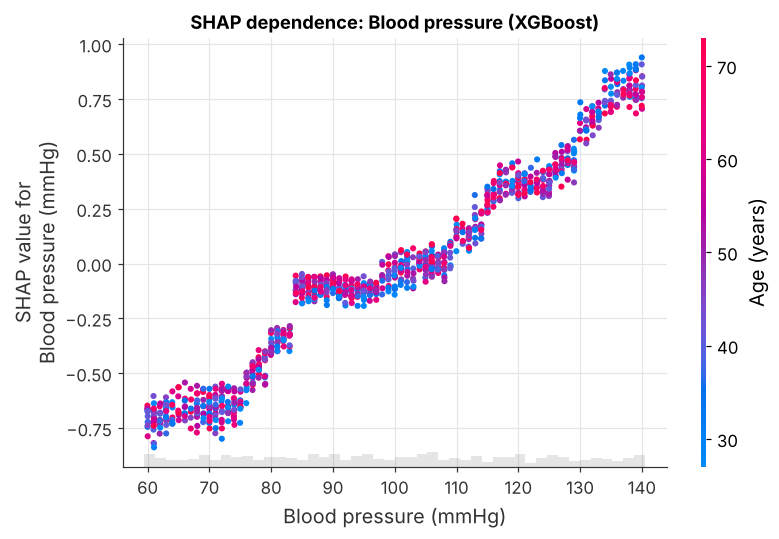

In [7]:
e_xgb = expl_by_model["XGBoost"]
for feat, fname in [("Glucose (mg/dL)", "shap_dependence_glucose"), ("Blood pressure (mmHg)", "shap_dependence_bp")]:
    fig = explain.plot_dependence(e_xgb, feat, f"SHAP dependence: {feat.split(' (')[0]} (XGBoost)")
    viz.save_fig(fig, fname); plt.show()

Glucose pushes the prediction up almost in a straight line, from about −2 (very low glucose) to about +1.7 (very high glucose) on the log-odds scale. Because the real effect is nearly linear, a plain Logistic Regression can capture it, which explains why it matches the tree models.

### 3.4 Explaining single patients
The highest-risk and lowest-risk patients in the test set, explained by the selected model. Bars show how each feature moved the prediction away from the average (log-odds scale).

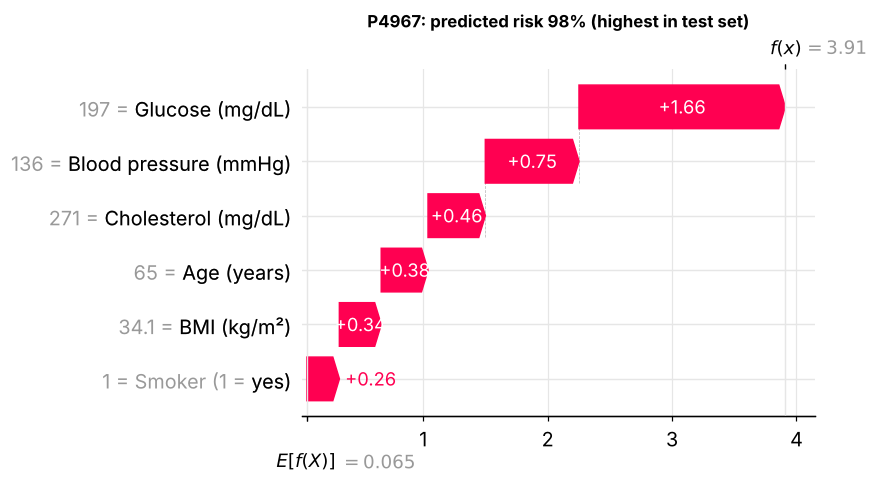

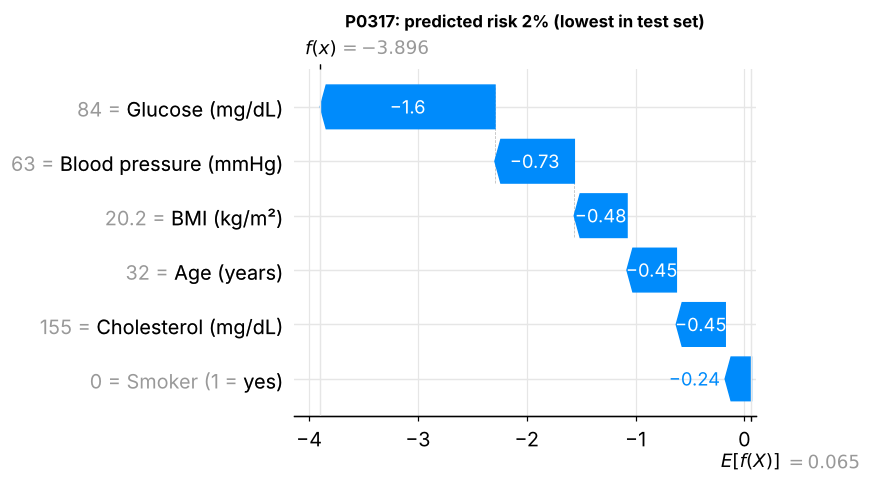

In [8]:
p_best = proba[best_name]
for label, i, fname in [("highest", int(p_best.argmax()), "shap_waterfall_high"), ("lowest", int(p_best.argmin()), "shap_waterfall_low")]:
    row = test.iloc[i]
    title = f"{row['patient_id']}: predicted risk {p_best[i]:.0%} ({label} in test set)"
    fig = explain.plot_waterfall(expl[i], title)
    viz.save_fig(fig, fname); plt.show()

The same explanation in plain **percentage points of risk** is what the Streamlit app shows to a user. Here it is for the highest-risk patient:

In [9]:
patient = test.iloc[int(p_best.argmax())][C.FEATURES].to_dict()
print("Patient:", patient)
print(predict.predict_patient(patient, model=best, meta=meta))
contrib = predict.explain_patient(patient, model=best)
print(f"Average predicted risk of reference patients: {contrib.attrs['base_probability']:.1%}")
contrib.round(2)

Patient: {'age': 65, 'bmi': 34.1, 'blood_pressure': 136, 'glucose': 197, 'cholesterol': 271, 'smoking': 1}
{'probability': 0.9803570549529658, 'predicted_label': 1, 'screening_flag': True, 'screening_threshold': 0.3884, 'risk_band': 'High risk', 'model': 'Logistic Regression'}
Average predicted risk of reference patients: 52.3%


,feature,value,contribution_pp
0,Glucose (mg/dL),197.0,21.87
1,Blood pressure (mmHg),136.0,8.06
2,Cholesterol (mg/dL),271.0,5.01
3,Age (years),65.0,4.22
4,BMI (kg/m²),34.1,3.70
5,Smoker (1 = yes),1.0,2.85


## 4 · Does the model work equally well for different groups?
We check ROC-AUC and recall (at the screening threshold) for age bands, smokers vs non-smokers, BMI bands and the two data sources. Groups are small, so small differences are noise.

In [10]:
def group_row(name, mask):
    m = mask.to_numpy()
    yy, pp = y_test.to_numpy()[m], p_best[m]
    flagged = pp >= threshold
    return {"group": name, "n": int(m.sum()), "disease share": yy.mean(),
            "ROC-AUC": roc_auc_score(yy, pp), "recall": flagged[yy == 1].mean(), "specificity": (~flagged[yy == 0]).mean()}

src = D.source_of(test)
groups = {
    "Age 25-39": test.age < 40, "Age 40-54": test.age.between(40, 54), "Age 55-75": test.age >= 55,
    "Non-smoker": test.smoking == 0, "Smoker": test.smoking == 1,
    "BMI < 25": test.bmi < 25, "BMI 25-29.9": (test.bmi >= 25) & (test.bmi < 30), "BMI >= 30": test.bmi >= 30,
    "Original rows": src == "original", "Synthetic rows": src == "synthetic",
}
sub = pd.DataFrame([group_row(n, m) for n, m in groups.items()]).set_index("group")
sub

,n,disease share,ROC-AUC,recall,specificity
group,,,,,
Age 25-39,279,0.412,0.815,0.783,0.726
Age 40-54,330,0.473,0.805,0.846,0.603
Age 55-75,391,0.586,0.831,0.895,0.562
Non-smoker,465,0.419,0.833,0.815,0.700
Smoker,535,0.570,0.800,0.879,0.548
BMI < 25,318,0.412,0.827,0.832,0.701
BMI 25-29.9,257,0.506,0.830,0.823,0.677
BMI >= 30,425,0.562,0.806,0.883,0.527
Original rows,100,0.390,0.501,0.641,0.410


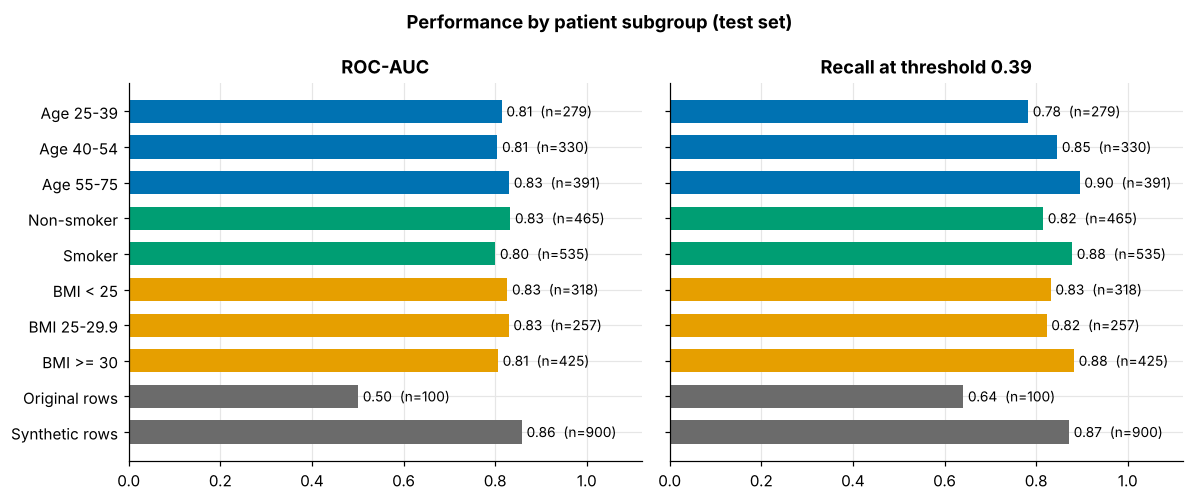

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
colors = [viz.BLUE] * 3 + [viz.GREEN] * 2 + [viz.ORANGE] * 3 + [viz.GREY] * 2
ypos = np.arange(len(sub))[::-1]
for ax, col in zip(axes, ["ROC-AUC", "recall"]):
    ax.barh(ypos, sub[col], color=colors, height=0.65)
    for yv, v, n in zip(ypos, sub[col], sub["n"]):
        ax.text(v + 0.01, yv, f"{v:.2f}  (n={n})", va="center", fontsize=9)
    ax.set(xlim=(0, 1.12), title=col if col == "ROC-AUC" else f"Recall at threshold {threshold:.2f}")
axes[0].set_yticks(ypos, sub.index)
fig.suptitle("Performance by patient subgroup (test set)", fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "subgroup_performance"); plt.show()

## 5 · Error analysis: who does the model miss?
At the screening threshold we compare sick patients who were **caught** (true positives) with sick patients who were **missed** (false negatives).

In [12]:
flagged = p_best >= threshold
caught = test[(y_test == 1) & flagged]
missed = test[(y_test == 1) & ~flagged]
cmp = pd.DataFrame({"caught (TP)": caught[C.FEATURES].mean(), "missed (FN)": missed[C.FEATURES].mean(),
                    "healthy (TN+FP)": test[y_test == 0][C.FEATURES].mean()})
print(f"Sick patients: {int((y_test == 1).sum())} | caught: {len(caught)} | missed: {len(missed)}")
cmp.round(2)

Sick patients: 500 | caught: 427 | missed: 73


,caught (TP),missed (FN),healthy (TN+FP)
age,52.82,47.25,47.78
bmi,29.83,28.06,27.80
blood_pressure,105.15,95.97,94.63
glucose,157.09,106.67,116.47
cholesterol,222.70,212.49,214.07
smoking,0.63,0.51,0.46


Missed patients look like healthy patients on the main drivers (especially glucose). That is expected: the model can only use the six features it is given. Anything that is not in those columns (family history, symptoms, lab values) is invisible to it.

## 6 · Key findings
1. **Selected model: Logistic Regression.** Test AUC 0.822 (95% interval 0.796 to 0.848). It is ahead of Random Forest by 0.006 (interval −0.001 to 0.014, so not clearly ahead) and ahead of XGBoost by 0.007 (interval 0.001 to 0.013, a very small edge). In practice the three models perform the same.
2. **Glucose dominates.** Shuffling glucose lowers the test AUC by 0.21, while the next feature (blood pressure) lowers it by only 0.04. In SHAP, glucose holds 38% to 47% of the total importance in all three models, and the ranking is the same everywhere: glucose, blood pressure, then age, BMI, cholesterol and smoking close together.
3. **The glucose effect is close to a straight line** in the XGBoost dependence plot, which is why the simple linear model keeps up with the tree models.
4. **Subgroups.** ROC-AUC stays between 0.80 and 0.83 across age, smoking and BMI groups. Recall at the screening cut-off is higher for older patients (0.90 for ages 55-75 vs 0.78 for ages 25-39), smokers (0.88 vs 0.82) and BMI 30 or more (0.88 vs 0.83), because these groups get higher scores overall. The price is lower specificity, meaning more false alarms. Each group has 250 to 540 patients, so gaps of a few points are within noise.
5. **The original rows are the exception.** On their 100 test rows the model has an AUC of 0.50 (recall 0.64, specificity 0.41). This matches notebooks 01 and 02: those labels carry no learnable signal.
6. **Missed patients.** The model misses 73 of 500 sick patients. Their average glucose is 107, close to the 116 of healthy patients and far below the 157 of caught patients. The model can only use the six columns it is given.
7. **Limits to remember.** The data is partly synthetic. One label covers several diseases. The blood-pressure type (systolic or diastolic) is unknown. The results come from one random split and have no external validation. The probabilities were not recalibrated. Because of all this, the model is a teaching demo and not a clinical tool.